In [4]:
from sklearn.datasets import make_classification
import numpy as np

In [40]:
total_point = 1000
total_feature = 2
epoch = 1000
lr = 0.01


In [41]:
X, y = make_classification(n_samples=total_point, n_features=total_feature, n_informative=1, n_redundant=0, n_classes=2, n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=10)

In [42]:
X

array([[-0.20535429, -2.86386516],
       [-0.31575309, -0.87698029],
       [-0.25640262, -2.47773077],
       ...,
       [-0.42153598,  0.16589003],
       [ 0.37325639,  0.47467773],
       [-0.06012331, -1.30409991]], shape=(1000, 2))

In [43]:
y

array([0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1,

In [44]:

import matplotlib.pyplot as plt

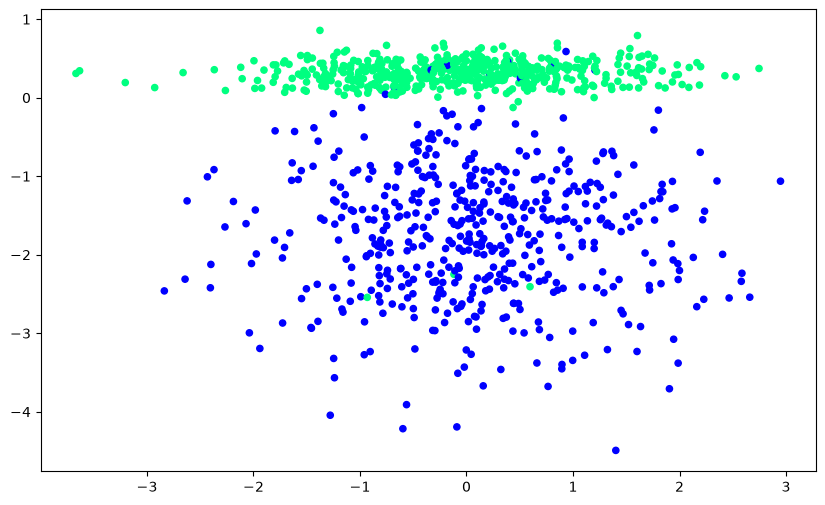

In [45]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0], X[:,1],c=y,cmap="winter",s=20)

In [46]:
np.insert(X,0,1) # Adding the W0 to 0 index

array([ 1.        , -0.20535429, -2.86386516, ...,  0.47467773,
       -0.06012331, -1.30409991], shape=(2001,))

In [47]:
weights = np.ones(3) # random start weights
weights

array([1., 1., 1.])

In [48]:
point_index = 54  # taking any random points

X[point_index]

array([-0.03148369, -1.95573987])

In [49]:
y[point_index]

np.int64(0)

In [50]:
np.insert(X[point_index],0,1)

array([ 1.        , -0.03148369, -1.95573987])

In [51]:
weights

array([1., 1., 1.])

In [52]:
def step_function(z):
    return 1 if z >= 0 else 0

In [53]:
z = np.dot(np.insert(X[point_index],0,1),weights) # doing the dot product

In [54]:
z

np.float64(-0.9872235639161152)

In [55]:
y_hat = step_function(z)
y_hat

0

In [56]:
y[point_index] - y_hat

np.int64(0)

In [62]:
def perceptron(X, y):
    X = np.insert(X, 0, 1, axis=1)  # adding W0 = 1 in every point
    weights = np.ones(X[0].shape)  # generating initial weight = [1,1,1]
    
    for i in range(epoch):
        index = np.random.randint(0, total_point-1)
        y_hat = step_function(np.dot(X[index], weights))
        weights = weights + lr * (y[index] - y_hat) * X[index]
    
    return weights[0], weights[1:]  # return b and [w1, w2]

In [63]:
intercept_,coef_ = perceptron(X,y)

In [64]:
print(coef_)
print(intercept_)

[0.25268911 1.31130599]
0.5699999999999996


In [65]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [66]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

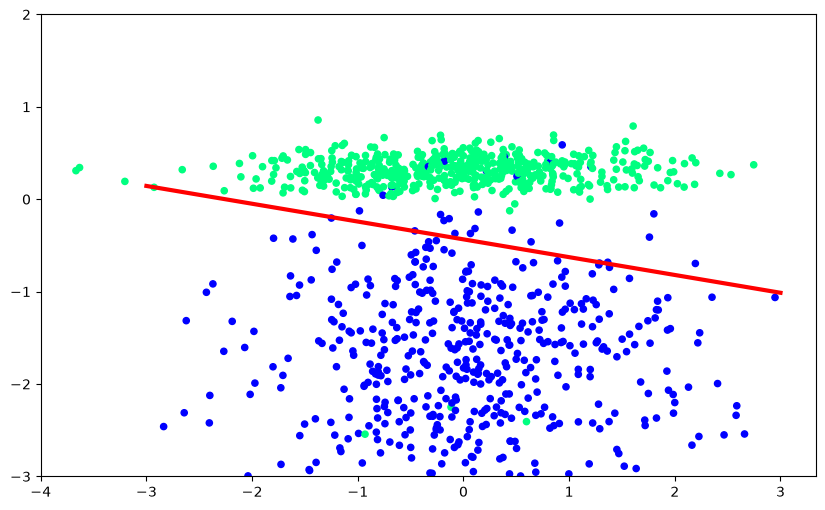

In [68]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=20)
plt.ylim(-3,2)